# expected-next-threat: demo

Every 0.2 s that a player holds the ball, the engine estimates what happens in the next second (keep it, pass, shoot or lose it), who would receive a pass and where a carry would end. It values each outcome with expected threat (xT) or expected goals (xG). The sum is the **expected next threat (ENT)**. A second output, `p_danger5`, is the probability of a box entry or a shot within the next 5 s of the same possession.

This notebook scores one SkillCorner open-data match (A-League 2024/25), follows the possession that led to a goal, and opens one frame of it.

**Note:** the pretrained models were trained on all 20 open-data matches, so the numbers here are in-sample. The out-of-match evaluation lives in the validation script.

In [1]:
# pip install expected-next-threat   (or, from a clone of the repo: pip install .)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from expected_next_threat import NextThreatEngine, load_match
from expected_next_threat.possessions import stitch_possessions

## 1. Load the engine and a match

The first call downloads the match from SkillCorner's public repository (about 95 MB) and caches it.

In [2]:
engine = NextThreatEngine.pretrained()
match = load_match(1996435)
teams = match.events[["team_id", "team_shortname"]].drop_duplicates().set_index("team_id").team_shortname
print(match.match_id, "|", " v ".join(teams.values), "|", match.nf, "frames")

1996435 | Adelaide United v Sydney FC | 57621 frames


## 2. Score every on-ball frame

In [3]:
live = engine.predict_match(match)
print(len(live), "on-ball frames")
live[["t", "carrier_slot", "p_keep", "p_pass", "p_shot", "ent_full", "p_danger5"]].head()

8145 on-ball frames


,t,carrier_slot,p_keep,p_pass,p_shot,ent_full,p_danger5
0,11.8,24,0.798049,0.194412,0.0001,0.005298,0.000200
1,12.0,24,0.647767,0.341972,0.0001,0.006623,0.000206
2,12.2,24,0.509212,0.482354,0.0001,0.007885,0.000366
3,12.4,24,0.432451,0.556634,0.0001,0.009254,0.000805
4,12.6,24,0.467942,0.519985,0.0001,0.008927,0.001202


Each row also splits ENT into its three parts. On average across the match:

In [4]:
parts = live[["ent_carry_part", "ent_pass_part", "ent_shot_part"]].sum()
(parts / parts.sum()).round(3)

ent_carry_part    0.457
ent_pass_part     0.485
ent_shot_part     0.058
dtype: float64

## 3. Follow the goal possession

The ENT line is what the engine expects next. The ball-xT line is the value of where the ball is now. Gaps are passes in flight, when nobody holds the ball.

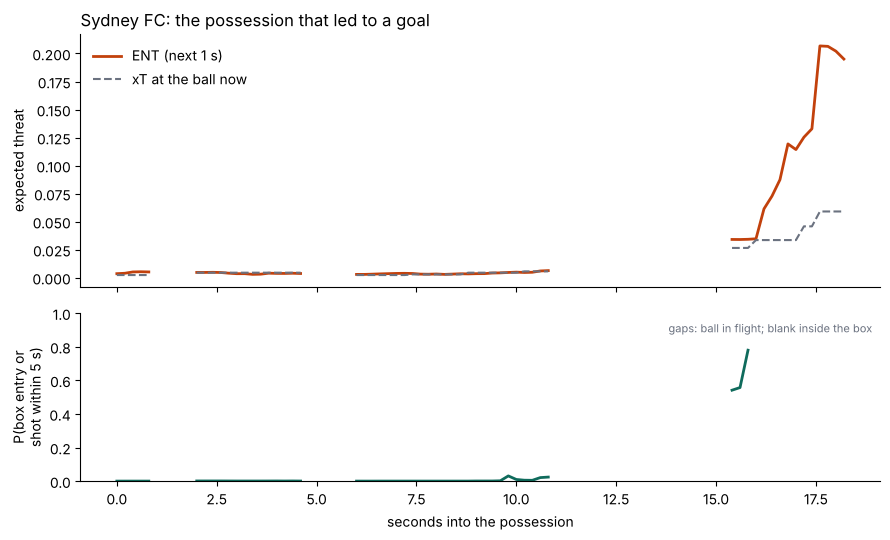

In [5]:
pp, tp = stitch_possessions(match.events)
goal_tp = pp[pp.lead_to_goal.fillna(False).astype(bool)].tp.unique()
poss = live[live.tp == goal_tp[3]].copy()          # the fourth goal possession of the match
poss["clock"] = poss.t - poss.t.iloc[0]
team = teams[poss.team_id.iloc[0]]
# break the lines where nobody holds the ball (passes in flight), so gaps are not drawn as data
gap = poss.clock.diff() > 0.25
plot = pd.concat([poss, poss[gap].assign(clock=poss.clock[gap] - 0.1, ent_full=np.nan, xt_here=np.nan, p_danger5=np.nan)]).sort_values("clock")

fig, ax = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))
ax[0].plot(plot.clock, plot.ent_full, color="#c2410c", lw=2, label="ENT (next 1 s)")
ax[0].plot(plot.clock, plot.xt_here, color="#6b7280", lw=1.5, ls="--", label="xT at the ball now")
ax[0].set_ylabel("expected threat"); ax[0].legend(frameon=False, loc="upper left")
ax[0].set_title(f"{team}: the possession that led to a goal", loc="left")
ax[1].plot(plot.clock, plot.p_danger5, color="#0f6b5c", lw=2)
ax[1].set_ylim(0, 1); ax[1].text(0.99, 0.95, "gaps: ball in flight; blank inside the box", transform=ax[1].transAxes, ha="right", va="top", fontsize=8, color="#6b7280"); ax[1].set_ylabel("P(box entry or\nshot within 5 s)"); ax[1].set_xlabel("seconds into the possession")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Open one frame

The frame where ENT peaks. Circle size is the probability that a team-mate receives the next pass; colour is the xT where he would receive it. The cross is where the carrier is expected to be in 1 s.

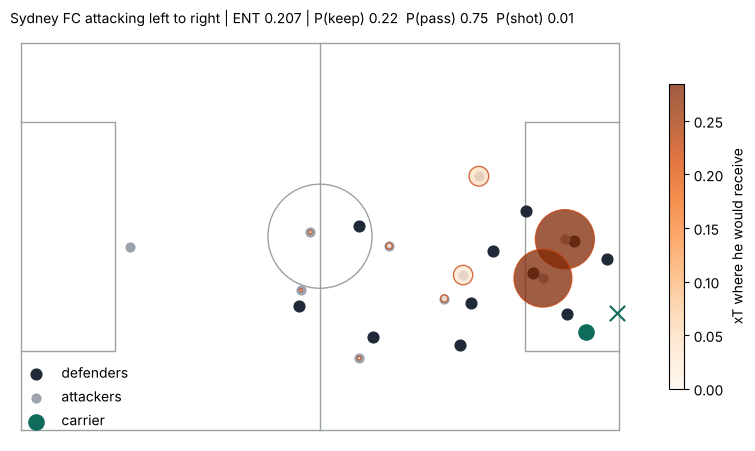

In [6]:
row = poss.loc[poss.ent_full.idxmax()]
f, s, cs = int(row.frame), float(row.sign), int(row.carrier_slot)
agg, cand = engine.pass_layer(match, poss.loc[[row.name]], return_candidates=True)
X, Y = match.X[f] * s, match.Y[f] * s
L, W = match.pitch_length, match.pitch_width
att = match.team == row.team_id

def pitch(ax):
    ax.set_facecolor("#f4f6f2")
    ax.plot([-L/2, L/2, L/2, -L/2, -L/2], [-W/2, -W/2, W/2, W/2, -W/2], color="#9aa3a0", lw=1)
    ax.plot([0, 0], [-W/2, W/2], color="#9aa3a0", lw=1)
    for sx in (-1, 1):
        ax.plot([sx*L/2, sx*(L/2-16.5), sx*(L/2-16.5), sx*L/2], [-20.16, -20.16, 20.16, 20.16], color="#9aa3a0", lw=1)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, color="#9aa3a0", lw=1))
    ax.set_xlim(-L/2-2, L/2+2); ax.set_ylim(-W/2-2, W/2+2); ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(10, 6.6)); pitch(ax)
ax.scatter(X[~att], Y[~att], s=60, color="#1f2937", zorder=3, label="defenders")
ax.scatter(X[att], Y[att], s=40, color="#9ca3af", zorder=3, label="attackers")
sc = ax.scatter(cand.x, cand.y, s=4000 * cand.p_receiver, c=cand.xt_target, cmap="Oranges", vmin=0, vmax=max(0.05, cand.xt_target.max()),
                edgecolor="#c2410c", alpha=0.75, zorder=4)
ax.scatter([X[cs]], [Y[cs]], s=120, color="#0f6b5c", zorder=5, label="carrier")
ax.scatter([row.cx + row.carry_dx], [row.cy + row.carry_dy_out * np.sign(row.cy + 1e-6)], marker="x", s=120, color="#0f6b5c", zorder=5)
plt.colorbar(sc, ax=ax, shrink=0.6, label="xT where he would receive")
ax.set_title(f"{team} attacking left to right | ENT {row.ent_full:.3f} | P(keep) {row.p_keep:.2f}  P(pass) {row.p_pass:.2f}  P(shot) {row.p_shot:.2f}", loc="left", fontsize=10)
ax.legend(frameon=False, loc="lower left"); plt.show()

The three most likely receivers at that moment:

In [7]:
names = match.players.set_index("player_id").short_name
top = cand.sort_values("p_receiver", ascending=False).head(3).assign(player=lambda d: d.player_id.map(names))
top[["player", "p_receiver", "xt_target"]].round(3)

,player,p_receiver,xt_target
0,P. Klimala,0.451,0.285
7,A. Segecic,0.434,0.285
3,J. Courtney-Perkins,0.050,0.046


## What the numbers mean

- `p_keep`, `p_pass`, `p_shot`, `p_other`: what the carrier does in the next 1 s. Calibrated on unseen matches; P(shot) is recalibrated with an isotonic map.
- `ent_pass`: expected xT where the next pass would be received, if a pass is played and arrives (no completion model).
- `v_carry`: expected xT where a 1 s carry would end.
- `ent_full`: the three combined.
- `p_danger5`: P(box entry or shot within 5 s), for frames with the ball outside the box.

These are forecasts, not judgements of players. With 20 matches, player-level rankings are not supported.